# IT3091 Machine Learning — Gold Price Forecasting

### Machine Learning-Based Gold Price Forecasting for Purchasing Decision Support in a Sri Lankan Jewellery Business

**Important:** This notebook uses a chronological time-series workflow. The target is the first available `Gold_LKR` observation on or after **7 calendar days after the current date**, so the forecast horizon is approximately seven days for market/trading-day data.

**Final workflow:** data understanding → preprocessing → merging → EDA → feature engineering → date-based future target → chronological split → five-model comparison → time-series cross-validation → hyperparameter tuning → multicollinearity check → final model selection → final test evaluation → residual analysis → model interpretation → business prediction.


In [1]:
# ============================================================
# GOLD PRICE FORECASTING
# 4 ML MODELS
# ============================================================

from pathlib import Path
import warnings
import json
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    ElasticNet
)

from xgboost import XGBRegressor

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV,
    cross_val_score
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    median_absolute_error,
    explained_variance_score
)

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

warnings.filterwarnings("ignore")

pd.set_option(
    "display.max_columns",
    None
)

pd.set_option(
    "display.width",
    180
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:

# PROJECT PATHS


def find_project_root():

    candidates = [
        Path.cwd()
    ] + list(Path.cwd().parents)

    for folder in candidates:

        if (
            (folder / "Raw Data").exists()
            and
            (folder / "Processed Data").exists()
        ):

            return folder

    raise FileNotFoundError(
        "Could not find Gold_Price_Project root. "
        "Make sure Raw Data and Processed Data folders exist."
    )


PROJECT_ROOT = find_project_root()

RAW_DATA = (
    PROJECT_ROOT / "Raw Data"
)

PROCESSED_DATA = (
    PROJECT_ROOT / "Processed Data"
)

OUTPUTS = (
    PROJECT_ROOT / "Outputs"
)

FIGURES = (
    OUTPUTS / "Figures"
)

DECISION_LOGS = (
    PROJECT_ROOT / "Decision Logs"
)

DATA_DICTIONARY = (
    PROJECT_ROOT / "Data_Dictionary"
)


for folder in [
    PROCESSED_DATA,
    OUTPUTS,
    FIGURES,
    DECISION_LOGS,
    DATA_DICTIONARY
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


print("Project Root:")
print(PROJECT_ROOT)

print("\nRaw Data:")
print(RAW_DATA)

print("\nOutputs:")
print(OUTPUTS)

Project Root:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project

Raw Data:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Raw Data

Outputs:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Outputs


In [3]:

# CHECK RAW DATA FILES


required_files = [
    "gold_data_daily_comprehensive_cleaned.csv",
    "USD_LKR.csv",
    "Gold_LKR.csv"
]

print("Required files:\n")

for filename in required_files:

    path = RAW_DATA / filename

    status = (
        "FOUND"
        if path.exists()
        else "NOT FOUND"
    )

    print(
        f"{filename}: {status}"
    )


print("\nFiles actually inside Raw Data:")

for file in sorted(
    RAW_DATA.iterdir()
):

    print(
        "-",
        file.name
    )

Required files:

gold_data_daily_comprehensive_cleaned.csv: FOUND
USD_LKR.csv: FOUND
Gold_LKR.csv: FOUND

Files actually inside Raw Data:
- gold_data_daily_comprehensive_cleaned.csv
- Gold_LKR.csv
- USD_LKR.csv


In [4]:

# LOAD RAW DATASETS


gold_raw = pd.read_csv(
    RAW_DATA
    / "gold_data_daily_comprehensive_cleaned.csv"
)

usd_lkr_raw = pd.read_csv(
    RAW_DATA
    / "USD_LKR.csv"
)

gold_lkr_raw = pd.read_csv(
    RAW_DATA
    / "Gold_LKR.csv"
)


print(
    "International Gold:",
    gold_raw.shape
)

print(
    "USD/LKR:",
    usd_lkr_raw.shape
)

print(
    "Gold LKR:",
    gold_lkr_raw.shape
)

International Gold: (6383, 20)
USD/LKR: (3485, 3)
Gold LKR: (3484, 3)


In [5]:

# DATA UNDERSTANDING


print("INTERNATIONAL GOLD COLUMNS")
print(
    gold_raw.columns.tolist()
)

print("\nUSD/LKR COLUMNS")
print(
    usd_lkr_raw.columns.tolist()
)

print("\nGOLD LKR COLUMNS")
print(
    gold_lkr_raw.columns.tolist()
)

INTERNATIONAL GOLD COLUMNS
['DateTime', 'Date', 'Year', 'Month', 'Day', 'DayOfWeek', 'Quarter', 'Open', 'High', 'Low', 'Close', 'Volume', 'Price_Change', 'Price_Change_Percent', 'MA_7', 'MA_30', 'MA_90', 'MA_365', 'Volatility_30d', 'Source']

USD/LKR COLUMNS
['Currency', 'Date', 'Exchange Rate']

GOLD LKR COLUMNS
['Currency', 'Date', 'Exchange Rate']


In [6]:

# SAMPLE RECORDS


print("INTERNATIONAL GOLD")
display(
    gold_raw.head()
)

print("\nUSD/LKR")
display(
    usd_lkr_raw.head()
)

print("\nGOLD LKR")
display(
    gold_lkr_raw.head()
)

INTERNATIONAL GOLD


,DateTime,Date,Year,Month,Day,DayOfWeek,Quarter,Open,High,Low,Close,Volume,Price_Change,Price_Change_Percent,MA_7,MA_30,MA_90,MA_365,Volatility_30d,Source
0,2000-08-30 00:00:00-04:00,2000-08-30,2000,8,30,Wednesday,3,273.899994,273.899994,273.899994,273.899994,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yahoo Finance
1,2000-08-31 00:00:00-04:00,2000-08-31,2000,8,31,Thursday,3,274.799988,278.299988,274.799988,278.299988,0,4.399994,1.606424,NaN,NaN,NaN,NaN,NaN,Yahoo Finance
2,2000-09-01 00:00:00-04:00,2000-09-01,2000,9,1,Friday,3,277.000000,277.000000,277.000000,277.000000,0,-1.299988,-0.467117,NaN,NaN,NaN,NaN,NaN,Yahoo Finance
3,2000-09-05 00:00:00-04:00,2000-09-05,2000,9,5,Tuesday,3,275.799988,275.799988,275.799988,275.799988,2,-1.200012,-0.433217,NaN,NaN,NaN,NaN,NaN,Yahoo Finance
4,2000-09-06 00:00:00-04:00,2000-09-06,2000,9,6,Wednesday,3,274.200012,274.200012,274.200012,274.200012,0,-1.599976,-0.580122,NaN,NaN,NaN,NaN,NaN,Yahoo Finance



USD/LKR


,Currency,Date,Exchange Rate
0,USD,2026-09-07,328.3421
1,USD,2026-09-04,328.3642
2,USD,2026-09-03,328.5890
3,USD,2026-09-02,328.0538
4,USD,2026-09-01,327.8963



GOLD LKR


,Currency,Date,Exchange Rate
0,XAU,2026-09-08,1.452306e+06
1,XAU,2026-09-07,1.447407e+06
2,XAU,2026-09-04,1.471349e+06
3,XAU,2026-09-03,1.449570e+06
4,XAU,2026-09-02,1.411989e+06


In [7]:

# DATA QUALITY CHECK


def quality_report(
    df,
    name
):

    print("=" * 60)

    print(name)

    print("=" * 60)

    print(
        "Rows:",
        len(df)
    )

    print(
        "Columns:",
        len(df.columns)
    )

    print(
        "Duplicate rows:",
        df.duplicated().sum()
    )

    print(
        "\nMissing values:"
    )

    display(
        df.isna()
        .sum()
        .sort_values(
            ascending=False
        )
        .head(15)
    )


quality_report(
    gold_raw,
    "International Gold"
)

quality_report(
    usd_lkr_raw,
    "USD/LKR"
)

quality_report(
    gold_lkr_raw,
    "Gold LKR"
)

International Gold
Rows: 6383
Columns: 20
Duplicate rows: 0

Missing values:


MA_365                  364
MA_90                    89
Volatility_30d           30
MA_30                    29
MA_7                      6
Price_Change_Percent      1
Price_Change              1
DateTime                  0
Month                     0
Year                      0
Date                      0
Day                       0
Volume                    0
Close                     0
Low                       0
dtype: int64

USD/LKR
Rows: 3485
Columns: 3
Duplicate rows: 0

Missing values:


Currency         0
Date             0
Exchange Rate    0
dtype: int64

Gold LKR
Rows: 3484
Columns: 3
Duplicate rows: 0

Missing values:


Currency         0
Date             0
Exchange Rate    0
dtype: int64

In [8]:

# PREPROCESSING

gold = gold_raw.copy()
usd_lkr = usd_lkr_raw.copy()
gold_lkr = gold_lkr_raw.copy()



# Date conversion


for df in [
    gold,
    usd_lkr,
    gold_lkr
]:

    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )


# Remove invalid dates

gold = gold.dropna(
    subset=["Date"]
).copy()

usd_lkr = usd_lkr.dropna(
    subset=["Date"]
).copy()

gold_lkr = gold_lkr.dropna(
    subset=["Date"]
).copy()



# Rename exchange-rate columns


if "Exchange Rate" in usd_lkr.columns:

    usd_lkr = usd_lkr.rename(
        columns={
            "Exchange Rate":
            "USD_LKR"
        }
    )


if "Exchange Rate" in gold_lkr.columns:

    gold_lkr = gold_lkr.rename(
        columns={
            "Exchange Rate":
            "Gold_LKR"
        }
    )



# Convert numeric columns


def convert_numeric(
    df
):

    for column in df.columns:

        if column != "Date":

            df[column] = pd.to_numeric(
                df[column],
                errors="coerce"
            )

    return df


gold = convert_numeric(
    gold
)

usd_lkr = convert_numeric(
    usd_lkr
)

gold_lkr = convert_numeric(
    gold_lkr
)


# Remove duplicates


gold = (
    gold
    .drop_duplicates()
    .copy()
)

usd_lkr = (
    usd_lkr
    .drop_duplicates()
    .copy()
)

gold_lkr = (
    gold_lkr
    .drop_duplicates()
    .copy()
)


# Sort chronologically


gold = (
    gold
    .sort_values("Date")
    .reset_index(drop=True)
)

usd_lkr = (
    usd_lkr
    .sort_values("Date")
    .reset_index(drop=True)
)

gold_lkr = (
    gold_lkr
    .sort_values("Date")
    .reset_index(drop=True)
)


print("Preprocessing completed.")

Preprocessing completed.


In [9]:

# STANDARDIZE INTERNATIONAL GOLD COLUMNS


required_gold_columns = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

missing_gold_columns = [
    column
    for column
    in required_gold_columns
    if column not in gold.columns
]

if missing_gold_columns:

    raise ValueError(
        "Missing international gold columns:\n"
        + str(
            missing_gold_columns
        )
    )


if "USD_LKR" not in usd_lkr.columns:

    raise ValueError(
        "USD_LKR column was not found."
    )


if "Gold_LKR" not in gold_lkr.columns:

    raise ValueError(
        "Gold_LKR column was not found."
    )


gold = gold[
    required_gold_columns
].copy()


usd_lkr = usd_lkr[
    [
        "Date",
        "USD_LKR"
    ]
].copy()


gold_lkr = gold_lkr[
    [
        "Date",
        "Gold_LKR"
    ]
].copy()


display(
    gold.head()
)

display(
    usd_lkr.head()
)

display(
    gold_lkr.head()
)

,Date,Open,High,Low,Close,Volume
0,2000-08-30,273.899994,273.899994,273.899994,273.899994,0
1,2000-08-31,274.799988,278.299988,274.799988,278.299988,0
2,2000-09-01,277.000000,277.000000,277.000000,277.000000,0
3,2000-09-05,275.799988,275.799988,275.799988,275.799988,2
4,2000-09-06,274.200012,274.200012,274.200012,274.200012,0


,Date,USD_LKR
0,2010-05-07,113.6975
1,2010-05-11,113.6292
2,2010-05-12,113.6854
3,2010-05-13,113.7009
4,2010-05-14,113.6573


,Date,Gold_LKR
0,2010-05-07,136459.7395
1,2010-05-11,136684.5647
2,2010-05-12,139577.2499
3,2010-05-13,140790.1394
4,2010-05-14,140514.5200


In [10]:

# MERGE THREE DATA SOURCES


model_df = pd.merge(
    gold,
    usd_lkr,
    on="Date",
    how="inner"
)

model_df = pd.merge(
    model_df,
    gold_lkr,
    on="Date",
    how="inner"
)


model_df = (
    model_df
    .sort_values("Date")
    .reset_index(drop=True)
)


print(
    "Merged dataset shape:",
    model_df.shape
)

print(
    "\nDate range:"
)

print(
    model_df["Date"].min()
)

print(
    model_df["Date"].max()
)


display(
    model_df.head()
)

Merged dataset shape: (3246, 8)

Date range:
2010-05-07 00:00:00
2026-02-06 00:00:00


,Date,Open,High,Low,Close,Volume,USD_LKR,Gold_LKR
0,2010-05-07,1210.000000,1210.800049,1194.599976,1210.000000,112,113.6975,136459.7395
1,2010-05-11,1219.900024,1233.500000,1201.500000,1219.900024,201,113.6292,136684.5647
2,2010-05-12,1242.699951,1246.500000,1227.099976,1242.699951,213,113.6854,139577.2499
3,2010-05-13,1235.300049,1240.000000,1228.699951,1228.800049,37,113.7009,140790.1394
4,2010-05-14,1227.400024,1227.400024,1227.400024,1227.400024,99,113.6573,140514.5200


In [11]:

# POST-MERGE DATA QUALITY


print("Missing values:")

display(
    model_df
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
)


print(
    "\nDuplicate dates:",
    model_df["Date"]
    .duplicated()
    .sum()
)

Missing values:


Date        0
Open        0
High        0
Low         0
Close       0
Volume      0
USD_LKR     0
Gold_LKR    0
dtype: int64


Duplicate dates: 0


In [12]:
# MISSING VALUE HANDLING


# Forward fill only.
# We do NOT use backward fill because that could introduce
# future information into earlier observations.

numeric_columns = (
    model_df
    .select_dtypes(
        include=np.number
    )
    .columns
)


model_df[
    numeric_columns
] = (
    model_df[
        numeric_columns
    ]
    .ffill()
)


model_df = (
    model_df
    .dropna()
    .reset_index(drop=True)
)


print(
    "Rows after missing-value handling:",
    len(model_df)
)

Rows after missing-value handling: 3246


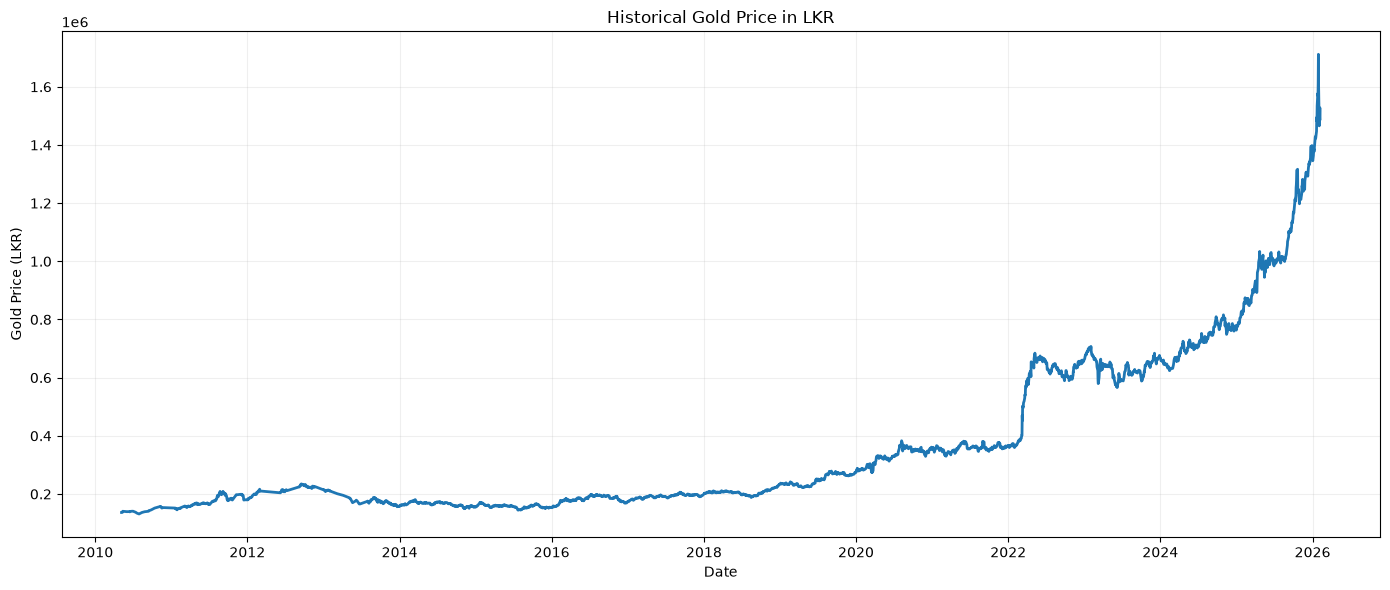

In [13]:

# EDA — GOLD PRICE TREND


plt.figure(
    figsize=(14, 6)
)

plt.plot(
    model_df["Date"],
    model_df["Gold_LKR"],
    linewidth=2
)

plt.title(
    "Historical Gold Price in LKR"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Gold Price (LKR)"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.show()

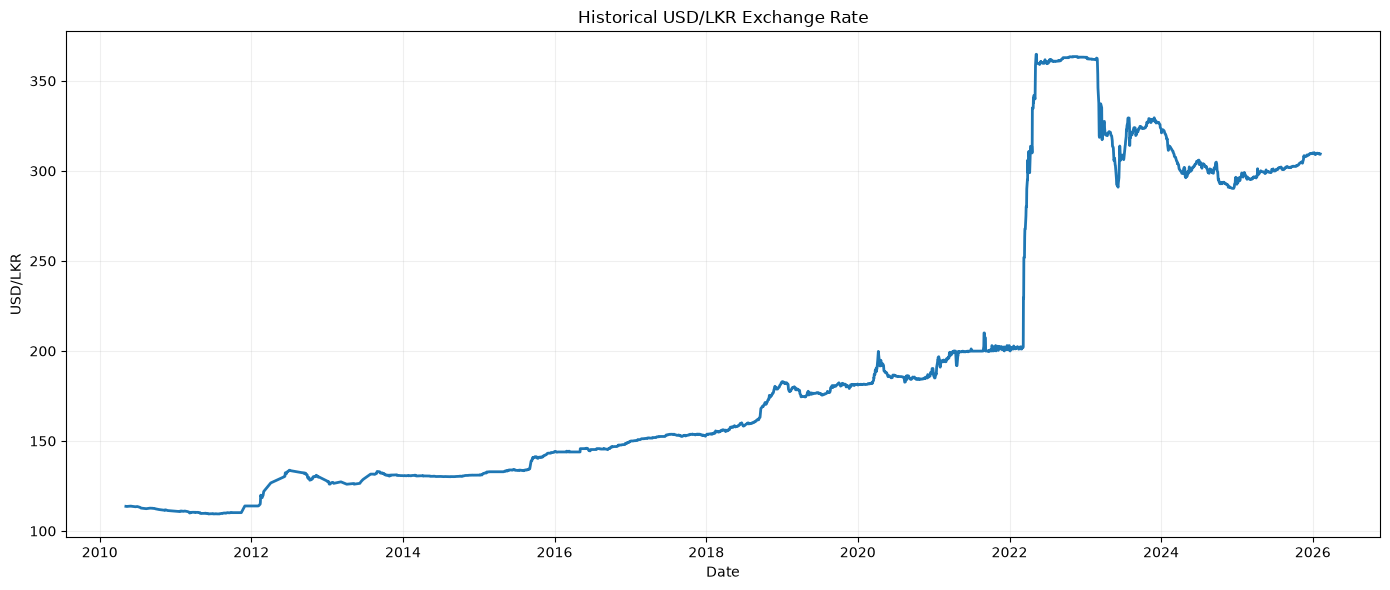

In [ ]:

# EDA — USD/LKR TREND


plt.figure(
    figsize=(14, 6)
)

plt.plot(
    model_df["Date"],
    model_df["USD_LKR"],
    linewidth=2
)

plt.title(
    "Historical USD/LKR Exchange Rate"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "USD/LKR"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.show()

Feature engineering

In [15]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================
# All engineered predictors use information available on or
# before the reference date. No future target values are used.

# -----------------------------
# 1. International gold movement
# -----------------------------
model_df["Price_Change"] = model_df["Close"].diff()
model_df["Price_Change_Percent"] = model_df["Close"].pct_change()
model_df["High_Low_Spread"] = model_df["High"] - model_df["Low"]
model_df["Close_Open_Spread"] = model_df["Close"] - model_df["Open"]

# -----------------------------
# 2. Gold LKR lag features
# -----------------------------
for lag in [1, 2, 3, 5, 7, 14, 30]:
    model_df[f"Gold_LKR_Lag_{lag}"] = model_df["Gold_LKR"].shift(lag)

# -----------------------------
# 3. International gold lag features
# -----------------------------
for lag in [1, 2, 7, 14]:
    model_df[f"Gold_Close_Lag_{lag}"] = model_df["Close"].shift(lag)

# -----------------------------
# 4. USD/LKR lag features
# -----------------------------
for lag in [1, 2, 7, 14]:
    model_df[f"USD_LKR_Lag_{lag}"] = model_df["USD_LKR"].shift(lag)

# -----------------------------
# 5. Leakage-safe rolling statistics
# -----------------------------
for window in [7, 14, 30]:
    previous_gold = model_df["Gold_LKR"].shift(1)
    model_df[f"Gold_LKR_MA_{window}"] = previous_gold.rolling(window).mean()
    model_df[f"Gold_LKR_STD_{window}"] = previous_gold.rolling(window).std()

previous_usd = model_df["USD_LKR"].shift(1)
model_df["USD_LKR_MA_7"] = previous_usd.rolling(7).mean()
model_df["USD_LKR_STD_7"] = previous_usd.rolling(7).std()

# Exponential moving average based only on previous observations
model_df["Gold_LKR_EMA_7"] = (
    model_df["Gold_LKR"].shift(1).ewm(span=7, adjust=False).mean()
)

# -----------------------------
# 6. Returns / momentum
# -----------------------------
for period in [1, 7, 14]:
    model_df[f"Gold_LKR_Return_{period}"] = model_df["Gold_LKR"].pct_change(period)

for period in [1, 7]:
    model_df[f"USD_LKR_Return_{period}"] = model_df["USD_LKR"].pct_change(period)
    model_df[f"Gold_Close_Return_{period}"] = model_df["Close"].pct_change(period)

# -----------------------------
# 7. International gold volatility
# -----------------------------
model_df["Gold_Close_Volatility_7"] = (
    model_df["Close"].pct_change().shift(1).rolling(7).std()
)

# -----------------------------
# 8. Cross-market relationship
# -----------------------------
# This ratio is calculated only from values known at the reference date.
model_df["Gold_LKR_to_International_Gold_Ratio"] = (
    model_df["Gold_LKR"] / model_df["Close"].replace(0, np.nan)
)

# Gold price relative to its previous 7-day average
model_df["Gold_LKR_vs_MA7"] = (
    model_df["Gold_LKR"] /
    model_df["Gold_LKR_MA_7"].replace(0, np.nan)
)

model_df = (
    model_df
    .replace([np.inf, -np.inf], np.nan)
    .sort_values("Date")
    .reset_index(drop=True)
)

print("Feature engineering completed successfully.")
print("New feature columns:")
for column in [c for c in model_df.columns if c not in ["Date", "Open", "High", "Low", "Close", "Volume", "USD_LKR", "Gold_LKR"]]:
    print("-", column)


Feature engineering completed successfully.
New feature columns:
- Price_Change
- Price_Change_Percent
- High_Low_Spread
- Close_Open_Spread
- Gold_LKR_Lag_1
- Gold_LKR_Lag_2
- Gold_LKR_Lag_3
- Gold_LKR_Lag_5
- Gold_LKR_Lag_7
- Gold_LKR_Lag_14
- Gold_LKR_Lag_30
- Gold_Close_Lag_1
- Gold_Close_Lag_2
- Gold_Close_Lag_7
- Gold_Close_Lag_14
- USD_LKR_Lag_1
- USD_LKR_Lag_2
- USD_LKR_Lag_7
- USD_LKR_Lag_14
- Gold_LKR_MA_7
- Gold_LKR_STD_7
- Gold_LKR_MA_14
- Gold_LKR_STD_14
- Gold_LKR_MA_30
- Gold_LKR_STD_30
- USD_LKR_MA_7
- USD_LKR_STD_7
- Gold_LKR_EMA_7
- Gold_LKR_Return_1
- Gold_LKR_Return_7
- Gold_LKR_Return_14
- USD_LKR_Return_1
- Gold_Close_Return_1
- USD_LKR_Return_7
- Gold_Close_Return_7
- Gold_Close_Volatility_7
- Gold_LKR_to_International_Gold_Ratio
- Gold_LKR_vs_MA7


In [16]:
# ============================================================
# FEATURE ENGINEERING LOG — ASSIGNMENT EVIDENCE
# ============================================================

feature_engineering_log = pd.DataFrame([
    ["Gold_LKR_Lag_1/2/3/5/7/14/30", "Previous Gold LKR values", "Capture short- and medium-term price persistence", "Safe — historical only"],
    ["Gold_Close_Lag_1/2/7/14", "Previous international gold prices", "Capture international gold-market movement", "Safe — historical only"],
    ["USD_LKR_Lag_1/2/7/14", "Previous USD/LKR values", "Capture exchange-rate movement affecting local gold value", "Safe — historical only"],
    ["Gold_LKR_MA_7/14/30", "Previous rolling mean of Gold LKR", "Capture local price trend at multiple horizons", "Safe — shifted before rolling"],
    ["Gold_LKR_STD_7/14/30", "Previous rolling standard deviation", "Measure local gold-price volatility", "Safe — shifted before rolling"],
    ["USD_LKR_MA_7", "Previous 7-observation USD/LKR mean", "Smooth short-term exchange-rate movement", "Safe — historical only"],
    ["Gold_LKR_EMA_7", "Previous-observation exponential moving average", "Give more weight to recent historical prices", "Safe — historical only"],
    ["Gold_LKR_Return_1/7/14", "Gold LKR percentage changes", "Represent short- and medium-term momentum", "Safe — current and past only"],
    ["USD_LKR_Return_1/7", "USD/LKR percentage changes", "Represent exchange-rate momentum", "Safe — current and past only"],
    ["High_Low_Spread", "International High minus Low", "Capture daily international gold trading range", "Safe — reference-date information"],
    ["Close_Open_Spread", "International Close minus Open", "Capture daily market direction", "Safe — reference-date information"],
    ["Gold_Close_Volatility_7", "Rolling volatility of international gold returns", "Measure recent international market risk", "Safe — shifted before rolling"],
    ["Gold_LKR_to_International_Gold_Ratio", "Gold LKR divided by international gold Close", "Capture cross-market relationship", "Safe — reference-date information"],
    ["Gold_LKR_vs_MA7", "Current Gold LKR relative to previous 7-day mean", "Capture whether price is above/below recent trend", "Safe — historical rolling mean"]
], columns=["Feature", "Construction", "Purpose", "Leakage Status"])

display(feature_engineering_log)
feature_engineering_log.to_csv(
    DECISION_LOGS / "feature_engineering_log.csv",
    index=False
)
print("Feature engineering log saved:", DECISION_LOGS / "feature_engineering_log.csv")


,Feature,Construction,Purpose,Leakage Status
0,Gold_LKR_Lag_1/2/3/5/7/14/30,Previous Gold LKR values,Capture short- and medium-term price persistence,Safe — historical only
1,Gold_Close_Lag_1/2/7/14,Previous international gold prices,Capture international gold-market movement,Safe — historical only
2,USD_LKR_Lag_1/2/7/14,Previous USD/LKR values,Capture exchange-rate movement affecting local...,Safe — historical only
3,Gold_LKR_MA_7/14/30,Previous rolling mean of Gold LKR,Capture local price trend at multiple horizons,Safe — shifted before rolling
4,Gold_LKR_STD_7/14/30,Previous rolling standard deviation,Measure local gold-price volatility,Safe — shifted before rolling
5,USD_LKR_MA_7,Previous 7-observation USD/LKR mean,Smooth short-term exchange-rate movement,Safe — historical only
6,Gold_LKR_EMA_7,Previous-observation exponential moving average,Give more weight to recent historical prices,Safe — historical only
7,Gold_LKR_Return_1/7/14,Gold LKR percentage changes,Represent short- and medium-term momentum,Safe — current and past only
8,USD_LKR_Return_1/7,USD/LKR percentage changes,Represent exchange-rate momentum,Safe — current and past only
9,High_Low_Spread,International High minus Low,Capture daily international gold trading range,Safe — reference-date information


Feature engineering log saved: c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Decision Logs\feature_engineering_log.csv


In [17]:

# TARGET CREATION
# APPROXIMATELY 7 CALENDAR DAYS AHEAD


future_lookup = (

    model_df[
        [
            "Date",
            "Gold_LKR"
        ]
    ]

    .dropna()

    .sort_values(
        "Date"
    )

    .rename(
        columns={
            "Date":
            "Target_Date",

            "Gold_LKR":
            "Target_Gold_LKR_7D"
        }
    )
)


target_dates = (

    model_df[
        ["Date"]
    ]

    .drop_duplicates()

    .sort_values(
        "Date"
    )

    .copy()
)


target_dates[
    "Desired_Target_Date"
] = (

    target_dates["Date"]

    + pd.Timedelta(
        days=7
    )
)


target_lookup = pd.merge_asof(

    target_dates,

    future_lookup,

    left_on=
        "Desired_Target_Date",

    right_on=
        "Target_Date",

    direction=
        "forward"
)


target_lookup = target_lookup[
    [
        "Date",
        "Desired_Target_Date",
        "Target_Date",
        "Target_Gold_LKR_7D"
    ]
]


model_df = model_df.merge(

    target_lookup,

    on="Date",

    how="left"
)


model_df[
    "Forecast_Horizon_Days"
] = (

    model_df[
        "Target_Date"
    ]

    - model_df[
        "Date"
    ]

).dt.days


display(
    model_df[
        [
            "Date",
            "Gold_LKR",
            "Desired_Target_Date",
            "Target_Date",
            "Forecast_Horizon_Days",
            "Target_Gold_LKR_7D"
        ]
    ].head(15)
)

,Date,Gold_LKR,Desired_Target_Date,Target_Date,Forecast_Horizon_Days,Target_Gold_LKR_7D
0,2010-05-07,136459.7395,2010-05-14,2010-05-14,7.0,140514.5200
1,2010-05-11,136684.5647,2010-05-18,2010-06-01,21.0,138925.9756
2,2010-05-12,139577.2499,2010-05-19,2010-06-01,20.0,138925.9756
3,2010-05-13,140790.1394,2010-05-20,2010-06-01,19.0,138925.9756
4,2010-05-14,140514.5200,2010-05-21,2010-06-01,18.0,138925.9756
5,2010-06-01,138925.9756,2010-06-08,2010-06-14,13.0,139614.4402
6,2010-06-02,139221.1373,2010-06-09,2010-06-14,12.0,139614.4402
7,2010-06-14,139614.4402,2010-06-21,2010-06-22,8.0,140534.6525
8,2010-06-15,138580.5544,2010-06-22,2010-06-22,7.0,140534.6525
9,2010-06-22,140534.6525,2010-06-29,2010-07-01,9.0,140839.8690


In [18]:

# TARGET HORIZON CHECK


print(
    model_df[
        "Forecast_Horizon_Days"
    ]
    .describe()
)


print(
    "\nTarget rows with missing future price:"
)

print(
    model_df[
        "Target_Gold_LKR_7D"
    ]
    .isna()
    .sum()
)

count    3242.000000
mean        7.551511
std         3.260750
min         7.000000
25%         7.000000
50%         7.000000
75%         7.000000
max        65.000000
Name: Forecast_Horizon_Days, dtype: float64

Target rows with missing future price:
4


In [19]:
# ============================================================
# MODEL FEATURES
# ============================================================

candidate_features = [
    # Current/reference-day market information
    "Open", "High", "Low", "Close", "Volume",
    "Price_Change", "Price_Change_Percent",
    "High_Low_Spread", "Close_Open_Spread",
    "USD_LKR", "Gold_LKR",

    # Gold LKR lags
    "Gold_LKR_Lag_1", "Gold_LKR_Lag_2", "Gold_LKR_Lag_3",
    "Gold_LKR_Lag_5", "Gold_LKR_Lag_7", "Gold_LKR_Lag_14", "Gold_LKR_Lag_30",

    # International gold lags
    "Gold_Close_Lag_1", "Gold_Close_Lag_2", "Gold_Close_Lag_7", "Gold_Close_Lag_14",

    # USD/LKR lags
    "USD_LKR_Lag_1", "USD_LKR_Lag_2", "USD_LKR_Lag_7", "USD_LKR_Lag_14",

    # Rolling trend / volatility
    "Gold_LKR_MA_7", "Gold_LKR_MA_14", "Gold_LKR_MA_30",
    "Gold_LKR_STD_7", "Gold_LKR_STD_14", "Gold_LKR_STD_30",
    "USD_LKR_MA_7", "USD_LKR_STD_7", "Gold_LKR_EMA_7",

    # Returns / momentum
    "Gold_LKR_Return_1", "Gold_LKR_Return_7", "Gold_LKR_Return_14",
    "USD_LKR_Return_1", "USD_LKR_Return_7",
    "Gold_Close_Return_1", "Gold_Close_Return_7",
    "Gold_Close_Volatility_7",

    # Cross-market features
    "Gold_LKR_to_International_Gold_Ratio",
    "Gold_LKR_vs_MA7"
]

features = [
    column for column in candidate_features
    if column in model_df.columns
]

TARGET = "Target_Gold_LKR_7D"

print("Number of features:", len(features))
print("\nFeatures:")
for feature in features:
    print("-", feature)

print("\nTarget:", TARGET)


Number of features: 45

Features:
- Open
- High
- Low
- Close
- Volume
- Price_Change
- Price_Change_Percent
- High_Low_Spread
- Close_Open_Spread
- USD_LKR
- Gold_LKR
- Gold_LKR_Lag_1
- Gold_LKR_Lag_2
- Gold_LKR_Lag_3
- Gold_LKR_Lag_5
- Gold_LKR_Lag_7
- Gold_LKR_Lag_14
- Gold_LKR_Lag_30
- Gold_Close_Lag_1
- Gold_Close_Lag_2
- Gold_Close_Lag_7
- Gold_Close_Lag_14
- USD_LKR_Lag_1
- USD_LKR_Lag_2
- USD_LKR_Lag_7
- USD_LKR_Lag_14
- Gold_LKR_MA_7
- Gold_LKR_MA_14
- Gold_LKR_MA_30
- Gold_LKR_STD_7
- Gold_LKR_STD_14
- Gold_LKR_STD_30
- USD_LKR_MA_7
- USD_LKR_STD_7
- Gold_LKR_EMA_7
- Gold_LKR_Return_1
- Gold_LKR_Return_7
- Gold_LKR_Return_14
- USD_LKR_Return_1
- USD_LKR_Return_7
- Gold_Close_Return_1
- Gold_Close_Return_7
- Gold_Close_Volatility_7
- Gold_LKR_to_International_Gold_Ratio
- Gold_LKR_vs_MA7

Target: Target_Gold_LKR_7D


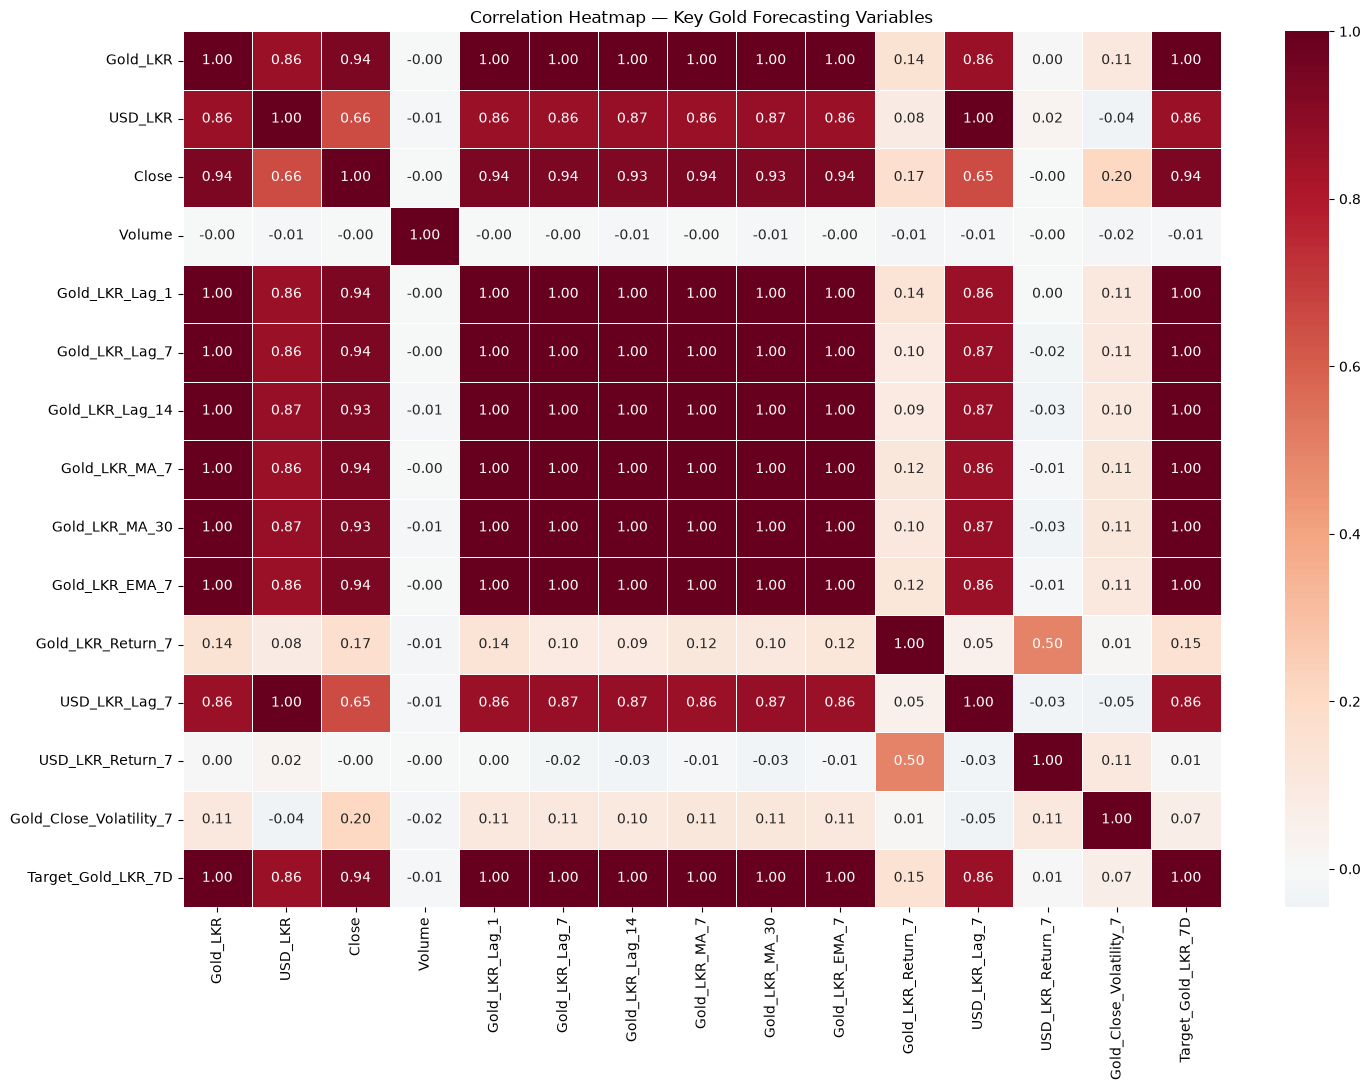

Correlation heatmap saved:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Outputs\Figures\correlation_heatmap_gold_forecasting.png


In [20]:
# ============================================================
# CORRELATION HEATMAP — EDA
# ============================================================
# Pearson correlation is used to examine linear relationships
# between important numeric variables and the 7-day target.
# This is an EDA tool, not a causal analysis.

heatmap_columns = [
    "Gold_LKR",
    "USD_LKR",
    "Close",
    "Volume",
    "Gold_LKR_Lag_1",
    "Gold_LKR_Lag_7",
    "Gold_LKR_Lag_14",
    "Gold_LKR_MA_7",
    "Gold_LKR_MA_30",
    "Gold_LKR_EMA_7",
    "Gold_LKR_Return_7",
    "USD_LKR_Lag_7",
    "USD_LKR_Return_7",
    "Gold_Close_Volatility_7",
    "Target_Gold_LKR_7D"
]

heatmap_columns = [
    c for c in heatmap_columns
    if c in model_df.columns
]

correlation_matrix = model_df[heatmap_columns].corr()

plt.figure(figsize=(15, 11))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    square=False
)

plt.title("Correlation Heatmap — Key Gold Forecasting Variables")
plt.tight_layout()

heatmap_path = FIGURES / "correlation_heatmap_gold_forecasting.png"
plt.savefig(heatmap_path, dpi=200, bbox_inches="tight")
plt.show()

print("Correlation heatmap saved:")
print(heatmap_path)


In [21]:

# LEAKAGE CHECK


assert (
    TARGET not in features
), (
    "LEAKAGE ERROR: target is included as a feature."
)


future_columns = [
    "Target_Gold_LKR_7D",
    "Target_Date",
    "Desired_Target_Date"
]


leakage_features = [
    feature
    for feature
    in features
    if feature
    in future_columns
]


assert (
    len(leakage_features) == 0
), (
    "LEAKAGE ERROR: future target information "
    "is present in features."
)


print(
    "Leakage check PASSED."
)

Leakage check PASSED.


Final modelling dataset

In [22]:

# FINAL MODELLING DATASET


model_df = (

    model_df

    .dropna(
        subset=
        features
        + [
            TARGET,
            "Target_Date"
        ]
    )

    .sort_values(
        "Date"
    )

    .reset_index(
        drop=True
    )
)


print(
    "Final modelling shape:",
    model_df.shape
)


print(
    "\nDate range:"
)

print(
    model_df["Date"].min()
)

print(
    model_df["Date"].max()
)


display(
    model_df[
        [
            "Date"
        ]
        + features
        + [
            TARGET
        ]
    ].head()
)

Final modelling shape: (3212, 50)

Date range:
2011-01-21 00:00:00
2026-01-30 00:00:00


,Date,Open,High,Low,Close,Volume,Price_Change,Price_Change_Percent,High_Low_Spread,Close_Open_Spread,USD_LKR,Gold_LKR,Gold_LKR_Lag_1,Gold_LKR_Lag_2,Gold_LKR_Lag_3,Gold_LKR_Lag_5,Gold_LKR_Lag_7,Gold_LKR_Lag_14,Gold_LKR_Lag_30,Gold_Close_Lag_1,Gold_Close_Lag_2,Gold_Close_Lag_7,Gold_Close_Lag_14,USD_LKR_Lag_1,USD_LKR_Lag_2,USD_LKR_Lag_7,USD_LKR_Lag_14,Gold_LKR_MA_7,Gold_LKR_MA_14,Gold_LKR_MA_30,Gold_LKR_STD_7,Gold_LKR_STD_14,Gold_LKR_STD_30,USD_LKR_MA_7,USD_LKR_STD_7,Gold_LKR_EMA_7,Gold_LKR_Return_1,Gold_LKR_Return_7,Gold_LKR_Return_14,USD_LKR_Return_1,USD_LKR_Return_7,Gold_Close_Return_1,Gold_Close_Return_7,Gold_Close_Volatility_7,Gold_LKR_to_International_Gold_Ratio,Gold_LKR_vs_MA7,Target_Gold_LKR_7D
0,2011-01-21,1341.699951,1345.599976,1338.599976,1341.000000,20,-5.500000,-0.004085,7.000000,-0.699951,110.9594,149467.8598,151674.4725,153272.6444,151716.6616,155882.8800,156365.8692,139433.7831,136459.7395,1346.500000,1372.900024,1399.099976,1248.300049,110.8124,111.3637,111.5843,112.6897,154176.710443,150031.133257,143696.637310,2257.510643,6277.620030,7580.142923,111.489471,0.320037,152448.914936,-0.014548,-0.044115,0.071963,0.001327,-0.005600,-0.004085,-0.041527,0.018386,111.460000,0.969458,145569.0589
1,2011-01-24,1352.300049,1352.300049,1341.800049,1344.500000,2,3.500000,0.002610,10.500000,-7.800049,111.0139,149841.0115,149467.8598,151674.4725,153272.6444,153187.1460,157137.2994,140727.0854,136684.5647,1341.000000,1346.500000,1403.099976,1269.699951,110.9594,110.8124,111.6845,112.6132,153191.280529,150747.853021,144130.241320,2619.207238,5499.178244,7523.738023,111.400200,0.372097,151703.651152,0.002497,-0.046433,0.064763,0.000491,-0.006004,0.002610,-0.041765,0.018395,111.447387,0.978130,148825.4982
2,2011-01-25,1330.400024,1331.500000,1323.599976,1332.300049,394,-12.199951,-0.009074,7.900024,1.900024,110.9216,147864.0389,149841.0115,149467.8598,151674.4725,151716.6616,155882.8800,142794.6853,139577.2499,1344.500000,1341.000000,1365.400024,1266.699951,111.0139,110.9594,111.6000,112.5431,152148.953686,151398.847743,144568.789547,2206.414898,4703.566223,7457.922056,111.304400,0.373027,151237.991239,-0.013194,-0.051441,0.035501,-0.000831,-0.006079,-0.009074,-0.024242,0.018376,110.984038,0.971837,149481.8615
3,2011-01-26,1333.000000,1341.699951,1333.000000,1333.000000,4,0.699951,0.000525,8.699951,0.000000,110.9091,148041.4667,147864.0389,149841.0115,149467.8598,153272.6444,153187.1460,143904.6413,140790.1394,1332.300049,1344.500000,1368.400024,1272.400024,110.9216,111.0139,111.6850,112.5442,151003.404957,151760.944429,144845.015847,2018.329177,4153.160278,7420.037205,111.207486,0.371552,150394.503154,0.001200,-0.033591,0.028747,-0.000113,-0.006947,0.000525,-0.025870,0.016085,111.058865,0.980385,149481.8615
4,2011-01-27,1342.000000,1342.000000,1318.400024,1318.400024,210699,-14.599976,-0.010953,23.599976,-23.599976,111.0493,149250.2592,148041.4667,147864.0389,149841.0115,151674.4725,151716.6616,145591.2093,140514.5200,1333.000000,1332.300049,1338.300049,1296.699951,110.9091,110.9216,111.6964,112.3064,150268.307914,152056.431957,145086.726757,2027.465399,3670.299288,7401.477396,111.096643,0.317101,149806.244041,0.008165,-0.016257,0.025132,0.001264,-0.005793,-0.010953,-0.014870,0.016000,113.205595,0.993225,149481.8615


Save processed modelling dataset

In [23]:

# SAVE PROCESSED DATA


modeling_path = (
    PROCESSED_DATA
    / "final_modeling_dataset_4_models.csv"
)


model_df.to_csv(
    modeling_path,
    index=False
)


print(
    "Saved:",
    modeling_path
)

Saved: c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Processed Data\final_modeling_dataset_4_models.csv


Chronological train / validation / test split

In [24]:

# CHRONOLOGICAL SPLIT


N = len(
    model_df
)


TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15


train_end = int(
    N * TRAIN_RATIO
)


validation_end = int(
    N *
    (
        TRAIN_RATIO
        + VALIDATION_RATIO
    )
)


train_df = (
    model_df
    .iloc[
        :train_end
    ]
    .copy()
)


validation_df = (
    model_df
    .iloc[
        train_end:validation_end
    ]
    .copy()
)


test_df = (
    model_df
    .iloc[
        validation_end:
    ]
    .copy()
)


print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    validation_df.shape
)

print(
    "Test:",
    test_df.shape
)


print(
    "\nTrain period:"
)

print(
    train_df["Date"].min(),
    "to",
    train_df["Date"].max()
)


print(
    "\nValidation period:"
)

print(
    validation_df["Date"].min(),
    "to",
    validation_df["Date"].max()
)


print(
    "\nTest period:"
)

print(
    test_df["Date"].min(),
    "to",
    test_df["Date"].max()
)

Train: (2248, 50)
Validation: (482, 50)
Test: (482, 50)

Train period:
2011-01-21 00:00:00 to 2021-12-17 00:00:00

Validation period:
2021-12-20 00:00:00 to 2024-01-05 00:00:00

Test period:
2024-01-08 00:00:00 to 2026-01-30 00:00:00


Prepare X and y

In [25]:

# X / y


X_train = train_df[
    features
].copy()

y_train = train_df[
    TARGET
].copy()


X_validation = validation_df[
    features
].copy()

y_validation = validation_df[
    TARGET
].copy()


X_test = test_df[
    features
].copy()

y_test = test_df[
    TARGET
].copy()


print(
    "X_train:",
    X_train.shape
)

print(
    "X_validation:",
    X_validation.shape
)

print(
    "X_test:",
    X_test.shape
)

X_train: (2248, 45)
X_validation: (482, 45)
X_test: (482, 45)


In [26]:

# NAIVE BASELINE


naive_validation_predictions = (
    validation_df[
        "Gold_LKR"
    ].values
)


def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    mape = (
        mean_absolute_percentage_error(
            y_true,
            y_pred
        )
        * 100
    )

    median_ae = (
        median_absolute_error(
            y_true,
            y_pred
        )
    )

    explained_variance = (
        explained_variance_score(
            y_true,
            y_pred
        )
    )

    return {

        "MAE": mae,

        "RMSE": rmse,

        "R2": r2,

        "MAPE (%)": mape,

        "Median AE": median_ae,

        "Explained Variance":
            explained_variance
    }


naive_metrics = calculate_metrics(

    y_validation,

    naive_validation_predictions
)


print(
    "NAIVE BASELINE"
)

display(
    pd.DataFrame(
        [naive_metrics],
        index=["Naive Baseline"]
    )
)

NAIVE BASELINE


,MAE,RMSE,R2,MAPE (%),Median AE,Explained Variance
Naive Baseline,13159.335571,19427.960207,0.944485,2.210234,9326.19,0.945518


In [27]:

# DEFINE EXACTLY 4 ML MODELS


models = {

    "Linear Regression":

        Pipeline([

            (
                "scaler",
                StandardScaler()
            ),

            (
                "model",
                LinearRegression()
            )

        ]),


    "Ridge Regression":

        Pipeline([

            (
                "scaler",
                StandardScaler()
            ),

            (
                "model",
                Ridge()
            )

        ]),


    "Elastic Net":

        Pipeline([

            (
                "scaler",
                StandardScaler()
            ),

            (
                "model",
                ElasticNet(
                    max_iter=20000,
                    random_state=42
                )
            )

        ]),


    "XGBoost":

        XGBRegressor(

            objective=
                "reg:squarederror",

            random_state=42,

            n_jobs=-1,

            verbosity=0
        )
}


print(
    "Four ML models:"
)

for name in models:

    print(
        "-",
        name
    )

Four ML models:
- Linear Regression
- Ridge Regression
- Elastic Net
- XGBoost


Time-series cross-validation

In [28]:

# TIME-SERIES CROSS-VALIDATION


CV_SPLITS = 3

CV_GAP = 7


tscv = TimeSeriesSplit(

    n_splits=
        CV_SPLITS,

    gap=
        CV_GAP
)


print(
    tscv
)


print(
    "\nCross-validation splits:"
)


for fold, (
    train_index,
    validation_index
) in enumerate(
    tscv.split(X_train),
    start=1
):

    print(
        f"Fold {fold}:"
    )

    print(
        "  Train:",
        len(train_index)
    )

    print(
        "  Validation:",
        len(validation_index)
    )

TimeSeriesSplit(gap=7, max_train_size=None, n_splits=3, test_size=None)

Cross-validation splits:
Fold 1:
  Train: 555
  Validation: 562
Fold 2:
  Train: 1117
  Validation: 562
Fold 3:
  Train: 1679
  Validation: 562


Hyperparameter grids

In [29]:

# HYPERPARAMETER GRIDS


param_grids = {

    "Ridge Regression": {

        "model__alpha": [
            0.01,
            0.1,
            1,
            10,
            100
        ]
    },


    "Elastic Net": {

        "model__alpha": [
            0.0001,
            0.001,
            0.01,
            0.1
        ],

        "model__l1_ratio": [
            0.1,
            0.3,
            0.5,
            0.7,
            0.9
        ]
    },


    "XGBoost": {

        "n_estimators": [
            200,
            400
        ],

        "learning_rate": [
            0.03,
            0.05
        ],

        "max_depth": [
            2,
            3
        ],

        "subsample": [
            0.8,
            1.0
        ]
    }
}


print(
    "Hyperparameter grids created."
)

Hyperparameter grids created.


In [30]:

# HYPERPARAMETER TUNING


best_models = {}

best_parameters = {}

cv_results_summary = []


# ------------------------------------------------------------
# LINEAR REGRESSION
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 70
)

print(
    "TUNING / VALIDATING: Linear Regression"
)

print(
    "=" * 70
)


linear_model = models[
    "Linear Regression"
]


linear_cv_scores = cross_val_score(

    linear_model,

    X_train,

    y_train,

    cv=tscv,

    scoring=
        "neg_root_mean_squared_error",

    n_jobs=-1
)


linear_cv_rmse = (
    -linear_cv_scores.mean()
)


linear_model.fit(
    X_train,
    y_train
)


best_models[
    "Linear Regression"
] = linear_model


best_parameters[
    "Linear Regression"
] = {}


cv_results_summary.append({

    "Model":
        "Linear Regression",

    "CV RMSE":
        linear_cv_rmse,

    "CV RMSE Std":
        linear_cv_scores.std(),

    "Best Parameters":
        "No tunable hyperparameters"

})


print(
    "Mean CV RMSE:",
    linear_cv_rmse
)



# RIDGE / ELASTIC NET / XGBOOST


for name in [

    "Ridge Regression",

    "Elastic Net",

    "XGBoost"

]:

    print(
        "\n"
        + "=" * 70
    )

    print(
        "TUNING:",
        name
    )

    print(
        "=" * 70
    )


    search = GridSearchCV(

        estimator=
            models[name],

        param_grid=
            param_grids[name],

        scoring=
            "neg_root_mean_squared_error",

        cv=
            tscv,

        n_jobs=-1,

        refit=True,

        return_train_score=True,

        verbose=1
    )


    search.fit(
        X_train,
        y_train
    )


    best_models[name] = (
        search.best_estimator_
    )


    best_parameters[name] = (
        search.best_params_
    )


    best_cv_rmse = (
        -search.best_score_
    )


    cv_results_summary.append({

        "Model":
            name,

        "CV RMSE":
            best_cv_rmse,

        "CV RMSE Std":
            np.nan,

        "Best Parameters":
            str(
                search.best_params_
            )

    })


    print(
        "\nBest parameters:"
    )

    print(
        search.best_params_
    )


    print(
        "\nBest CV RMSE:"
    )

    print(
        best_cv_rmse
    )


cv_results_df = pd.DataFrame(
    cv_results_summary
)


display(
    cv_results_df
)


TUNING / VALIDATING: Linear Regression
Mean CV RMSE: 7230.898726113087

TUNING: Ridge Regression
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Best parameters:
{'model__alpha': 100}

Best CV RMSE:
6801.836236887717

TUNING: Elastic Net
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best parameters:
{'model__alpha': 0.1, 'model__l1_ratio': 0.5}

Best CV RMSE:
6770.948413888393

TUNING: XGBoost
Fitting 3 folds for each of 16 candidates, totalling 48 fits

Best parameters:
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}

Best CV RMSE:
35967.488029316635


,Model,CV RMSE,CV RMSE Std,Best Parameters
0,Linear Regression,7230.898726,4769.630034,No tunable hyperparameters
1,Ridge Regression,6801.836237,NaN,{'model__alpha': 100}
2,Elastic Net,6770.948414,NaN,"{'model__alpha': 0.1, 'model__l1_ratio': 0.5}"
3,XGBoost,35967.488029,NaN,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."


In [31]:

# CELL 33
# TRAIN vs VALIDATION COMPARISON


train_validation_results = []

for name, model in best_models.items():

    
    # TRAIN PREDICTIONS
    
    train_pred = model.predict(
        X_train
    )

    
    # VALIDATION PREDICTIONS
    
    validation_pred = model.predict(
        X_validation
    )

   
    # TRAIN METRICS
    
    train_metrics = calculate_metrics(
        y_train,
        train_pred
    )

    
    # VALIDATION METRICS
    
    validation_metrics = calculate_metrics(
        y_validation,
        validation_pred
    )

    train_validation_results.append({

        "Model": name,

        "Train MAE":
            train_metrics["MAE"],

        "Validation MAE":
            validation_metrics["MAE"],

        "Train RMSE":
            train_metrics["RMSE"],

        "Validation RMSE":
            validation_metrics["RMSE"],

        "Train R2":
            train_metrics["R2"],

        "Validation R2":
            validation_metrics["R2"],

        "Train MAPE (%)":
            train_metrics["MAPE (%)"],

        "Validation MAPE (%)":
            validation_metrics["MAPE (%)"]

    })


train_validation_df = pd.DataFrame(
    train_validation_results
)


display(
    train_validation_df
    .sort_values("Validation RMSE")
    .reset_index(drop=True)
)

,Model,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train R2,Validation R2,Train MAPE (%),Validation MAPE (%)
0,Linear Regression,3396.290428,13524.357499,4903.124804,19636.506594,0.994871,0.943287,1.514026,2.270594
1,Ridge Regression,3677.579409,19162.660803,5204.554902,25813.313128,0.994221,0.901997,1.651208,3.162343
2,Elastic Net,3692.863784,19489.514330,5219.730577,26124.506348,0.994187,0.899619,1.658485,3.213277
3,XGBoost,2451.195741,242647.663382,3231.265894,255896.101159,0.997772,-8.631216,1.144146,38.380919


In [32]:
# ============================================================
# FINAL MODEL SELECTION
# ============================================================

# Select using the validation set, not training accuracy.
ml_validation_results = train_validation_df.copy()

best_validation_row = (
    ml_validation_results
    .sort_values(["Validation RMSE", "Validation MAE"])
    .iloc[0]
)

best_model_name = best_validation_row["Model"]
selected_model = best_models[best_model_name]

print("BEST MODEL BASED ON VALIDATION RMSE:")
print(best_model_name)

print("\nBest validation RMSE:")
print(f"{best_validation_row['Validation RMSE']:,.2f}")

print("\nBest validation R2:")
print(f"{best_validation_row['Validation R2']:.4f}")

print("\nBest parameters:")
print(best_parameters[best_model_name])


BEST MODEL BASED ON VALIDATION RMSE:
Linear Regression

Best validation RMSE:
19,636.51

Best validation R2:
0.9433

Best parameters:
{}


In [33]:

# MULTICOLLINEARITY CHECK


X_vif = X_train.copy()


vif_rows = []


for i, feature in enumerate(
    X_vif.columns
):

    vif_value = (
        variance_inflation_factor(
            X_vif.values,
            i
        )
    )


    vif_rows.append({

        "Feature":
            feature,

        "VIF":
            vif_value

    })


vif_df = (

    pd.DataFrame(
        vif_rows
    )

    .sort_values(
        "VIF",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


display(
    vif_df
)


vif_df.to_csv(
    OUTPUTS
    / "vif_results_4_models.csv",

    index=False
)

,Feature,VIF
0,Close_Open_Spread,1.000800e+15
1,Open,2.836551e+07
2,Close,1.675030e+06
3,Price_Change_Percent,1.512228e+06
4,Gold_Close_Return_1,7.510203e+05
5,Gold_Close_Lag_1,4.074789e+05
6,Price_Change,3.742411e+05
7,Gold_LKR_MA_7,1.057948e+05
8,USD_LKR,5.946293e+04
9,High_Low_Spread,3.246097e+04


In [34]:
# ============================================================
# FINAL MODEL — SELECTED FROM VALIDATION
# ============================================================

# If Linear Regression is the validation winner, this will be
# the final model used by the dashboard. Otherwise the code
# keeps the objectively best validation model.
final_model = best_models[best_model_name]

X_train_validation = pd.concat(
    [X_train, X_validation],
    axis=0
)

y_train_validation = pd.concat(
    [y_train, y_validation],
    axis=0
)

final_model.fit(
    X_train_validation,
    y_train_validation
)

print("Final selected model trained successfully:", best_model_name)
print("Training rows:", len(X_train_validation))


Final selected model trained successfully: Linear Regression
Training rows: 2730


In [35]:

# FINAL UNSEEN TEST EVALUATION


test_predictions = final_model.predict(
    X_test
)

final_test_metrics = calculate_metrics(
    y_test,
    test_predictions
)

print("=" * 60)
print("FINAL TEST RESULTS - LINEAR REGRESSION")
print("=" * 60)

print(
    "MAE       :",
    f"{final_test_metrics['MAE']:,.2f}"
)

print(
    "RMSE      :",
    f"{final_test_metrics['RMSE']:,.2f}"
)

print(
    "R2        :",
    f"{final_test_metrics['R2']:.4f}"
)

print(
    "MAPE      :",
    f"{final_test_metrics['MAPE (%)']:.2f}%"
)

print(
    "Median AE :",
    f"{final_test_metrics['Median AE']:,.2f}"
)

print(
    "Explained Variance:",
    f"{final_test_metrics['Explained Variance']:.4f}"
)

FINAL TEST RESULTS - LINEAR REGRESSION
MAE       : 25,376.14
RMSE      : 35,799.76
R2        : 0.9764
MAPE      : 2.53%
Median AE : 18,136.13
Explained Variance: 0.9815


In [36]:

# TRAIN + VALIDATION VS UNSEEN TEST


train_validation_predictions = final_model.predict(
    X_train_validation
)

train_validation_metrics = calculate_metrics(
    y_train_validation,
    train_validation_predictions
)

comparison = pd.DataFrame([
    {
        "Dataset": "Train + Validation",
        "MAE": train_validation_metrics["MAE"],
        "RMSE": train_validation_metrics["RMSE"],
        "R2": train_validation_metrics["R2"],
        "MAPE (%)": train_validation_metrics["MAPE (%)"]
    },
    {
        "Dataset": "Unseen Test",
        "MAE": final_test_metrics["MAE"],
        "RMSE": final_test_metrics["RMSE"],
        "R2": final_test_metrics["R2"],
        "MAPE (%)": final_test_metrics["MAPE (%)"]
    }
])

display(comparison)

,Dataset,MAE,RMSE,R2,MAPE (%)
0,Train + Validation,5004.426535,8415.704963,0.997336,1.667607
1,Unseen Test,25376.138089,35799.755584,0.976414,2.532049


In [37]:

# OVERFITTING / GENERALISATION GAP


rmse_gap = (
    final_test_metrics["RMSE"]
    -
    train_validation_metrics["RMSE"]
)

r2_gap = (
    train_validation_metrics["R2"]
    -
    final_test_metrics["R2"]
)

print("RMSE Gap:", f"{rmse_gap:,.2f}")
print("R2 Gap:", f"{r2_gap:.4f}")

RMSE Gap: 27,384.05
R2 Gap: 0.0209


In [38]:

# SAVE FINAL MODEL


final_model_path = (
    OUTPUTS / "final_gold_price_model.joblib"
)

joblib.dump(
    final_model,
    final_model_path
)

print("Final model saved:")
print(final_model_path)

Final model saved:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Outputs\final_gold_price_model.joblib


In [39]:

# VERIFY SAVED MODEL


loaded_model = joblib.load(
    final_model_path
)

loaded_test_predictions = loaded_model.predict(
    X_test
)

loaded_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        loaded_test_predictions
    )
)

print(
    "Saved model loaded successfully."
)

print(
    "Loaded model Test RMSE:",
    f"{loaded_test_rmse:,.2f}"
)

Saved model loaded successfully.
Loaded model Test RMSE: 35,799.76


In [40]:
# ============================================================
# FINAL MODEL COEFFICIENTS / FEATURE IMPORTANCE
# ============================================================

if best_model_name in ["Linear Regression", "Ridge Regression", "Elastic Net"]:
    linear_model = final_model.named_steps["model"]
    coefficients = linear_model.coef_

    coefficient_df = pd.DataFrame({
        "Feature": features,
        "Coefficient": coefficients
    })

    coefficient_df["Absolute_Coefficient"] = coefficient_df["Coefficient"].abs()
    coefficient_df = (
        coefficient_df
        .sort_values("Absolute_Coefficient", ascending=False)
        .reset_index(drop=True)
    )

    display(coefficient_df)
    coefficient_df.to_csv(
        OUTPUTS / "final_model_coefficients.csv",
        index=False
    )
else:
    coefficient_df = pd.DataFrame()
    print("Coefficient table is not applicable to the selected non-linear model:", best_model_name)


,Feature,Coefficient,Absolute_Coefficient
0,Gold_LKR,145217.215715,145217.215715
1,Gold_LKR_EMA_7,134095.272353,134095.272353
2,Gold_LKR_MA_14,-103001.999276,103001.999276
3,Gold_LKR_to_International_Gold_Ratio,-101019.888715,101019.888715
4,USD_LKR_Lag_7,75121.273611,75121.273611
5,USD_LKR_MA_7,59425.368576,59425.368576
6,Gold_LKR_MA_7,-43795.986234,43795.986234
7,USD_LKR_Lag_2,-38961.702827,38961.702827
8,Gold_LKR_Lag_7,28471.561114,28471.561114
9,Gold_LKR_Lag_14,23651.459072,23651.459072


In [41]:
# ============================================================
# TOP 10 LINEAR MODEL FEATURES
# ============================================================

if not coefficient_df.empty:
    top_features = coefficient_df.head(10)
    display(top_features)
else:
    print("Top coefficient ranking is not applicable for", best_model_name)


,Feature,Coefficient,Absolute_Coefficient
0,Gold_LKR,145217.215715,145217.215715
1,Gold_LKR_EMA_7,134095.272353,134095.272353
2,Gold_LKR_MA_14,-103001.999276,103001.999276
3,Gold_LKR_to_International_Gold_Ratio,-101019.888715,101019.888715
4,USD_LKR_Lag_7,75121.273611,75121.273611
5,USD_LKR_MA_7,59425.368576,59425.368576
6,Gold_LKR_MA_7,-43795.986234,43795.986234
7,USD_LKR_Lag_2,-38961.702827,38961.702827
8,Gold_LKR_Lag_7,28471.561114,28471.561114
9,Gold_LKR_Lag_14,23651.459072,23651.459072


In [42]:

# FINAL TEST PREDICTIONS


final_predictions_df = pd.DataFrame({

    "Date":
        test_df["Date"].values,

    "Target_Date":
        test_df["Target_Date"].values,

    "Actual_Gold_LKR":
        y_test.values,

    "Predicted_Gold_LKR":
        test_predictions

})

final_predictions_df["Absolute_Error"] = (
    final_predictions_df["Actual_Gold_LKR"]
    -
    final_predictions_df["Predicted_Gold_LKR"]
).abs()

final_predictions_df["Percentage_Error"] = (
    final_predictions_df["Absolute_Error"]
    /
    final_predictions_df["Actual_Gold_LKR"]
    * 100
)

display(
    final_predictions_df.head(10)
)

,Date,Target_Date,Actual_Gold_LKR,Predicted_Gold_LKR,Absolute_Error,Percentage_Error
0,2024-01-08,2024-01-16,660648.2825,648801.833450,11846.449050,1.793155
1,2024-01-09,2024-01-16,660648.2825,650301.718215,10346.564285,1.566123
2,2024-01-10,2024-01-17,653193.5079,647548.039733,5645.468167,0.864287
3,2024-01-11,2024-01-18,645426.3493,644494.548350,931.800950,0.144370
4,2024-01-12,2024-01-19,649352.4691,655833.445999,6480.976899,0.998068
5,2024-01-16,2024-01-23,647486.0357,647917.807805,431.772105,0.066684
6,2024-01-17,2024-01-24,648183.2744,639536.344353,8646.930047,1.334025
7,2024-01-18,2024-01-26,645896.6328,643596.019476,2300.613324,0.356189
8,2024-01-19,2024-01-26,645896.6328,647586.822581,1690.189781,0.261681
9,2024-01-22,2024-01-29,642417.7175,643315.710726,897.993226,0.139783


In [43]:
final_predictions_df.to_csv(
    OUTPUTS / "final_test_predictions.csv",
    index=False
)

print("Prediction results saved.")

Prediction results saved.


In [44]:

# RESIDUAL ANALYSIS


residuals = (
    y_test.values
    -
    test_predictions
)

residual_df = pd.DataFrame({

    "Date":
        test_df["Date"].values,

    "Actual":
        y_test.values,

    "Predicted":
        test_predictions,

    "Residual":
        residuals

})

display(
    residual_df.head(10)
)

,Date,Actual,Predicted,Residual
0,2024-01-08,660648.2825,648801.833450,11846.449050
1,2024-01-09,660648.2825,650301.718215,10346.564285
2,2024-01-10,653193.5079,647548.039733,5645.468167
3,2024-01-11,645426.3493,644494.548350,931.800950
4,2024-01-12,649352.4691,655833.445999,-6480.976899
5,2024-01-16,647486.0357,647917.807805,-431.772105
6,2024-01-17,648183.2744,639536.344353,8646.930047
7,2024-01-18,645896.6328,643596.019476,2300.613324
8,2024-01-19,645896.6328,647586.822581,-1690.189781
9,2024-01-22,642417.7175,643315.710726,-897.993226


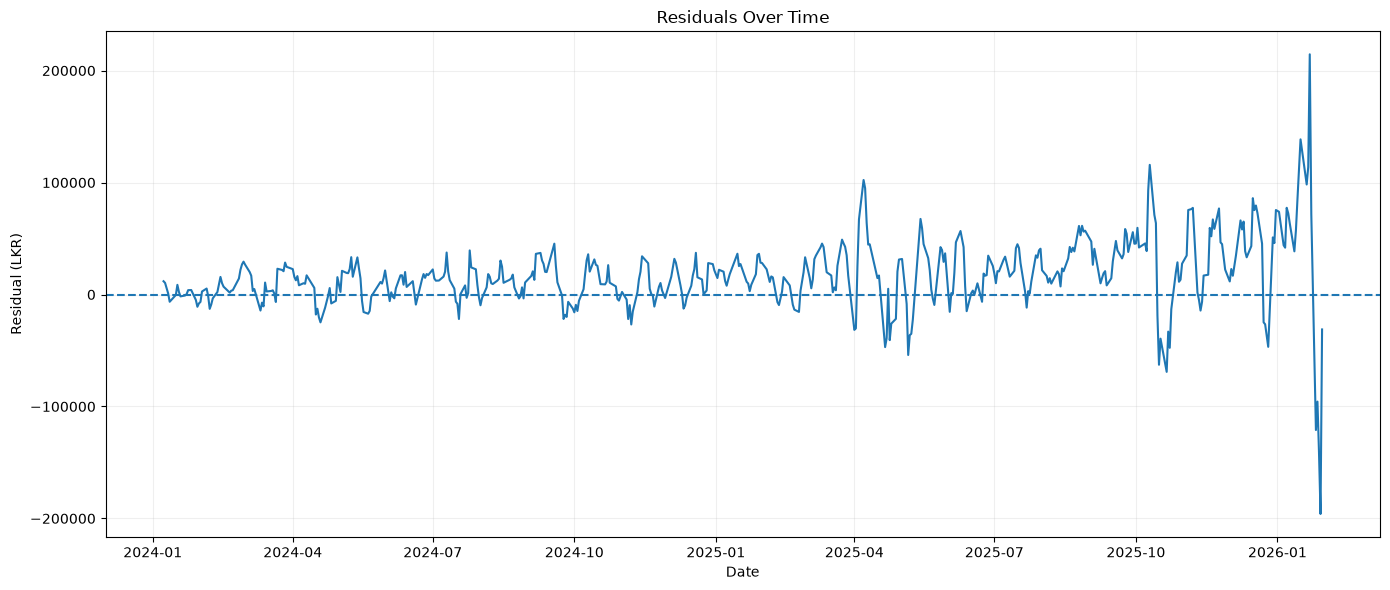

In [45]:
plt.figure(
    figsize=(14, 6)
)

plt.plot(
    residual_df["Date"],
    residual_df["Residual"],
    linewidth=1.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Residuals Over Time"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Residual (LKR)"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.show()

In [46]:

# FINAL MODEL METADATA 


import json

# Final selected model
best_model_name = best_model_name

# Get validation metrics directly from the comparison table
validation_row = train_validation_df[
    train_validation_df["Model"] == best_model_name
].iloc[0]

model_metadata = {

    "model_name":
        best_model_name,

    "target":
        "Target_Gold_LKR_7D",

    "forecast_horizon":
        "Approximately 7 calendar days",

    "features":
        features,

    "number_of_features":
        len(features),

    
    # Validation performance
    

    "validation_R2":
        float(
            validation_row["Validation R2"]
        ),

    "validation_RMSE":
        float(
            validation_row["Validation RMSE"]
        ),

    "validation_MAE":
        float(
            validation_row["Validation MAE"]
        ),

    "validation_MAPE":
        float(
            validation_row["Validation MAPE (%)"]
        ),

    
    # Final unseen test performance
    

    "test_R2":
        float(
            final_test_metrics["R2"]
        ),

    "test_RMSE":
        float(
            final_test_metrics["RMSE"]
        ),

    "test_MAE":
        float(
            final_test_metrics["MAE"]
        ),

    "test_MAPE":
        float(
            final_test_metrics["MAPE (%)"]
        ),

    
    # Train + Validation performance
    

    "train_validation_R2":
        float(
            train_validation_metrics["R2"]
        ),

    "train_validation_RMSE":
        float(
            train_validation_metrics["RMSE"]
        ),

    
    # Model file
    

    "model_file":
        "final_gold_price_model.joblib"
}


metadata_path = (
    OUTPUTS / "model_metadata.json"
)


with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        model_metadata,
        f,
        indent=4
    )


print("Model metadata saved successfully:")
print(metadata_path)

print("\nSelected Model:")
print(best_model_name)

print("\nTest R²:")
print(
    f"{final_test_metrics['R2']:.4f}"
)

print("\nTest MAPE:")
print(
    f"{final_test_metrics['MAPE (%)']:.2f}%"
)

Model metadata saved successfully:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Outputs\model_metadata.json

Selected Model:
Linear Regression

Test R²:
0.9764

Test MAPE:
2.53%


In [47]:
# ============================================================
# FINAL PROJECT OUTPUT CHECK
# ============================================================

print("=" * 70)
print("FINAL GOLD PRICE FORECASTING OUTPUT CHECK")
print("=" * 70)

print("\nSelected Model:")
print(best_model_name)

print("\nNumber of Features:")
print(len(features))

print("\nValidation Performance:")
print(f"RMSE : {validation_row['Validation RMSE']:,.2f}")
print(f"MAE  : {validation_row['Validation MAE']:,.2f}")
print(f"R²   : {validation_row['Validation R2']:.4f}")
print(f"MAPE : {validation_row['Validation MAPE (%)']:.2f}%")

print("\nUnseen Test Performance:")
print(f"RMSE : {final_test_metrics['RMSE']:,.2f}")
print(f"MAE  : {final_test_metrics['MAE']:,.2f}")
print(f"R²   : {final_test_metrics['R2']:.4f}")
print(f"MAPE : {final_test_metrics['MAPE (%)']:.2f}%")

print("\nGeneralisation Gap:")
print(f"RMSE Gap : {rmse_gap:,.2f}")
print(f"R² Gap   : {r2_gap:.4f}")

print("\nFinal Model File:")
print(final_model_path)

print("\nMetadata File:")
print(metadata_path)

print("\nProcessed Dataset:")
print(modeling_path)

print("\nFeature Engineering Log:")
print(DECISION_LOGS / "feature_engineering_log.csv")

print("\nCorrelation Heatmap:")
print(FIGURES / "correlation_heatmap_gold_forecasting.png")

print("\n" + "=" * 70)
print("NOTEBOOK FINAL OUTPUT CHECK COMPLETED")
print("=" * 70)

FINAL GOLD PRICE FORECASTING OUTPUT CHECK

Selected Model:
Linear Regression

Number of Features:
45

Validation Performance:
RMSE : 19,636.51
MAE  : 13,524.36
R²   : 0.9433
MAPE : 2.27%

Unseen Test Performance:
RMSE : 35,799.76
MAE  : 25,376.14
R²   : 0.9764
MAPE : 2.53%

Generalisation Gap:
RMSE Gap : 27,384.05
R² Gap   : 0.0209

Final Model File:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Outputs\final_gold_price_model.joblib

Metadata File:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Outputs\model_metadata.json

Processed Dataset:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Processed Data\final_modeling_dataset_4_models.csv

Feature Engineering Log:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Decision Logs\feature_engineering_log.csv

Correlation Heatmap:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Outputs\Figures\correlation_heatmap_gold_forecasting.png

N

In [48]:
# ============================================================
# DASHBOARD-READY REFERENCE DATA
# ============================================================

dashboard_data = model_df[
    ["Date", "Target_Date", "Gold_LKR"] + features
].copy()

dashboard_data = (
    dashboard_data
    .sort_values("Date")
    .reset_index(drop=True)
)

dashboard_data_path = (
    OUTPUTS / "dashboard_reference_data.csv"
)

dashboard_data.to_csv(
    dashboard_data_path,
    index=False
)

print("Dashboard reference data saved:")
print(dashboard_data_path)

print("\nAvailable reference dates:")
print(
    dashboard_data["Date"].min(),
    "to",
    dashboard_data["Date"].max()
)

print("\nRows available for dashboard:")
print(len(dashboard_data))

Dashboard reference data saved:
c:\Users\user\OneDrive\Desktop\Gold_Price_Project\Gold_Price_Project\Outputs\dashboard_reference_data.csv

Available reference dates:
2011-01-21 00:00:00 to 2026-01-30 00:00:00

Rows available for dashboard:
3212


In [53]:

# DASHBOARD FORECAST TEST


def dashboard_forecast(reference_date):

    reference_date = pd.Timestamp(reference_date)

    row = dashboard_data[
        dashboard_data["Date"] == reference_date
    ]

    if row.empty:
        raise ValueError(
            f"No model-ready data available for {reference_date.date()}"
        )

    prediction = final_model.predict(
        row[features]
    )[0]

    current_price = float(
        row["Gold_LKR"].iloc[0]
    )

    target_date = row["Target_Date"].iloc[0]

    change = prediction - current_price

    change_percent = (
        change / current_price
    ) * 100

    if change_percent > 1:
        recommendation = "BUY NOW"
    elif change_percent < -1:
        recommendation = "WAIT"
    else:
        recommendation = "MONITOR"

    return {
        "Reference Date":
            reference_date.strftime("%Y-%m-%d"),

        "Target Date":
            pd.Timestamp(target_date).strftime("%Y-%m-%d"),

        "Current Gold Price":
            current_price,

        "Predicted Gold Price":
            float(prediction),

        "Expected Change":
            float(change),

        "Expected Change (%)":
            float(change_percent),

        "Recommendation":
            recommendation,

        "Model":
            best_model_name
    }

In [54]:

# TEST DASHBOARD FORECAST


example_date = dashboard_data["Date"].iloc[-1]

result = dashboard_forecast(
    example_date
)

print("=" * 60)
print("DASHBOARD FORECAST TEST")
print("=" * 60)

for key, value in result.items():
    print(f"{key}: {value}")

DASHBOARD FORECAST TEST
Reference Date: 2026-01-30
Target Date: 2026-02-06
Current Gold Price: 1600736.5696
Predicted Gold Price: 1520677.3379483344
Expected Change: -80059.23165166564
Expected Change (%): -5.001399553936051
Recommendation: WAIT
Model: Linear Regression
